# Lp(a) Reddit Topic Modeling — V3 driver

## Setup

In [1]:
!pip install bertopic
!pip install llama-cpp-python
!pip install datamapplot
!pip install langdetect
from transformers import AutoTokenizer, AutoModel
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired
import torch
import pandas as pd
import time
import numpy as np
import click
import json
import umap
import hdbscan
import bertopic
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.representation import ZeroShotClassification
from bertopic.representation import OpenAI
from bertopic.representation import LiteLLM
from bertopic.representation import KeyBERTInspired, LlamaCPP
from bertopic.representation import LangChain
from huggingface_hub import hf_hub_download
import os
#from ctransformers import AutoModelForCausalLM
#from langchain_ollama import OllamaLLM
from llama_cpp import Llama
import importlib
import datamapplot

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 15.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.5/70.5 MB 38.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 5.2 MB/s eta 0:00:00
  Created wheel for llama-cpp-python: filename=llama_cpp_python-0.3.33-py3-none-linux_x86_64.whl size=20473680 sha256=87133f6beaee1db9fe4865507f5a38dcb87c8e8c7b8e8734e34f1c9729516824
  Stored in directory: /root/.cache/pip/wheels/13/fc/a3/e0214eb904e10e712ba0256988708e13188e9eddef8fbc5860
Successfully built llama-cpp-python
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 350.6/350.6 kB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 88.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Import



1.   List item
2.   List item



In [4]:
import sys, importlib
# Folder that CONTAINS the V3 'lpa_topic_modeling' package:
V3_PATH = '/content/drive/MyDrive/Lp(a) Reddit Topic Modeling V3'
if V3_PATH not in sys.path:
    sys.path.insert(0, V3_PATH)
import lpa_topic_modeling
importlib.reload(lpa_topic_modeling)
from lpa_topic_modeling import (TopicModeler, GroupLabeler, TopicClusterer,
                                fig1a_temporal, fig1b_clusters, fig_s2_silhouette, config)

## Paths

In [5]:
import os
BASE = '/content/drive/MyDrive/lpa_topic_modeling_MODELS'
DATA      = f'{BASE}/filtered_df_3.25.26.json'
METADATA  = f'{BASE}/metadata_3.28.26.json'
MODEL     = f'{BASE}/model_3.28.26.bertopic.pkl'
GROUPS    = f'{BASE}/group_summaries_3.30.26.json'
OUT = f'{BASE}/v3_out'; os.makedirs(OUT, exist_ok=True)
OUT_METADATA = f'{OUT}/metadata_reduced.pkl'
OUT_MODEL    = f'{OUT}/model_reduced.bertopic'
OUT_GROUPS   = f'{OUT}/group_summaries_reduced.json'

In [6]:
reddit_df = pd.read_json(DATA)
print(len(reddit_df), 'discussions')

34814 discussions


## Reduce outliers

In [6]:
#modeler = TopicModeler(enable_llm=False, seed=config.SEED)
#modeler.load_complete_state(METADATA, MODEL)
# reassign outliers (deterministic). Lower threshold -> fewer remaining outliers; try 0.0/0.1/0.2.
#modeler.reduce_outliers(strategy='c-tf-idf', threshold=0.1)
#modeler.save_complete_state(OUT_METADATA, OUT_MODEL)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

... (8 outputs left out)

2026-06-29 06:07:31,920 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers reduced: 9060 -> 5592 (16.1% of 34805) via 'c-tf-idf'


2026-06-29 06:08:24,559 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


Saved metadata -> /content/drive/MyDrive/lpa_topic_modeling_MODELS/v3_out/metadata_reduced.pkl; model -> /content/drive/MyDrive/lpa_topic_modeling_MODELS/v3_out/model_reduced.bertopic


##Load previously trained modeler/labeler


In [13]:
modeler = TopicModeler(enable_llm=False, seed=config.SEED)
modeler.load_complete_state(OUT_METADATA, OUT_MODEL)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded 34805 texts; 58 unique topics


In [7]:
# reuse the published LLM group labels, then refresh group sizes after outlier reduction
#labeler = GroupLabeler(modeler, preloaded_state=GROUPS)
#labeler.refresh_group_counts()
#labeler.save_group_summaries(OUT_GROUPS)
#for g, lab in labeler.current_labels().items():
#    print(g, '->', lab)

Loaded 10 groups from /content/drive/MyDrive/lpa_topic_modeling_MODELS/group_summaries_3.30.26.json
Saved group summaries -> /content/drive/MyDrive/lpa_topic_modeling_MODELS/v3_out/group_summaries_reduced.json
Group_2 -> ApoB and Lp(a) Testing for Cardiovascular Risk Assessment
Group_5 -> Nutrition and Exercise for Cardiovascular Health Promotion
Group_6 -> Lipid Management and Cardiovascular Risk Reduction Strategies
Group_9 -> Cardiovascular Risk Assessment and Unexplained Symptoms Investigation
Group_4 -> Hormone and Lipid Profile Analysis for Cardiovascular Risk Assessment
Group_3 -> Plant-Based Diets and Metabolic Health
Group_0 -> Lipidomics and Cardiovascular Disease Risk Factors
Group_8 -> Cholesterol Management and Oxidative Stress Mitigation
Group_7 -> Niacin and Lipoprotein(a) Effects on Cholesterol and Cardiovascular Disease
Group_1 -> PCSK9 Inhibitors for Hypercholesterolemia Management


In [15]:
labeler = GroupLabeler(modeler, preloaded_state=OUT_GROUPS)

Loaded 10 groups from /content/drive/MyDrive/lpa_topic_modeling_MODELS/v3_out/group_summaries_reduced.json


## Figures

Saved /content/drive/MyDrive/lpa_topic_modeling_MODELS/v3_out/fig1a_temporal_7.4.[pdf/eps/png/tiff]


Batches:   0%|          | 0/1088 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/lpa_topic_modeling_MODELS/v3_out/fig1b_clusters_7.4.[pdf/eps/png/tiff]


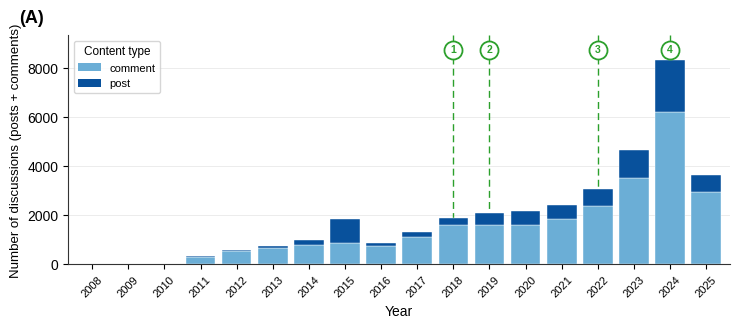

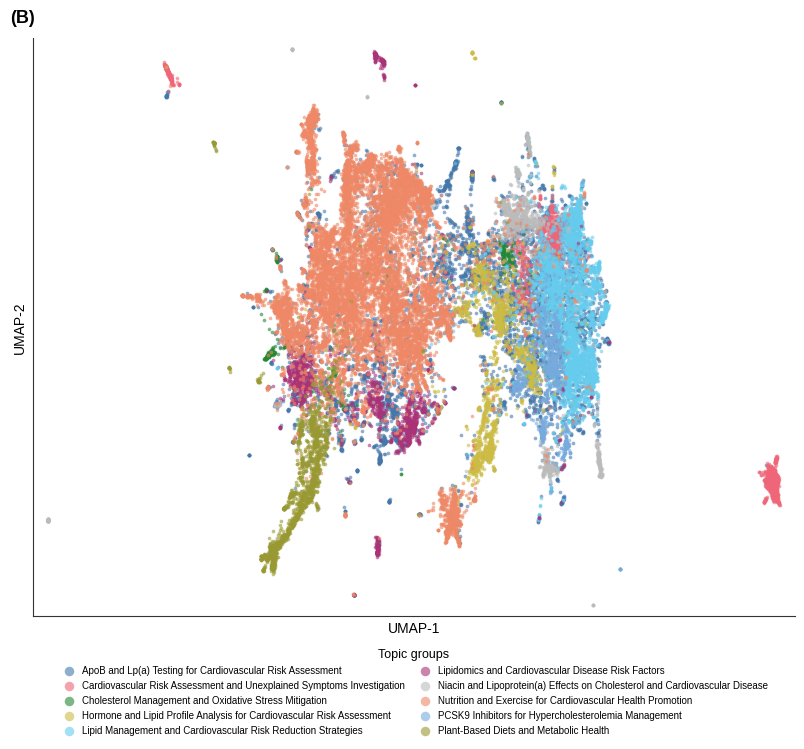

In [16]:
fig1a_temporal(reddit_df, out_path=f'{OUT}/fig1a_temporal_7.4.png')
fig1b, emb2d, labels = fig1b_clusters(modeler, labeler, out_path=f'{OUT}/fig1b_clusters_7.4.png')

In [9]:
# short legend labels; put the full group names in the figure caption
SHORT = {
 "ApoB and Lp(a) Testing for Cardiovascular Risk Assessment": "ApoB & Lp(a) testing",
 "Cardiovascular Risk Assessment and Unexplained Symptoms Investigation": "CV risk & unexplained symptoms",
 "Cholesterol Management and Oxidative Stress Mitigation": "Cholesterol mgmt & oxidative stress",
 "Hormone and Lipid Profile Analysis for Cardiovascular Risk Assessment": "Hormone & lipid profile",
 "Lipid Management and Cardiovascular Risk Reduction Strategies": "Lipid mgmt & CV risk reduction",
 "Lipidomics and Cardiovascular Disease Risk Factors": "Lipidomics & CVD risk factors",
 "Niacin and Lipoprotein(a) Effects on Cholesterol and Cardiovascular Disease": "Niacin & Lp(a) effects",
 "Nutrition and Exercise for Cardiovascular Health Promotion": "Nutrition & exercise",
 "PCSK9 Inhibitors for Hypercholesterolemia Management": "PCSK9 inhibitors",
 "Plant-Based Diets and Metabolic Health": "Plant-based diets & metabolic health",
}

fig, ax = plt.subplots(figsize=(7.0, 7.2))
for g in uniq:
    m = lab == g
    ax.scatter(xy[m,0], xy[m,1], c=[cmap[g]], s=7, alpha=0.6, linewidths=0,
               rasterized=True, label=SHORT.get(g, g))
ax.set_xlabel("UMAP-1", fontsize=10); ax.set_ylabel("UMAP-2", fontsize=10)
ax.set_xticks([]); ax.set_yticks([])
for sp in ("top","right"): ax.spines[sp].set_visible(False)
ax.margins(0.02)                                   # scatter fills the frame
ax.text(-0.03, 1.02, "(B)", transform=ax.transAxes, fontsize=13, fontweight="bold", va="bottom")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=2,
          fontsize=8, title="Topic groups", title_fontsize=9, frameon=False,
          markerscale=2.6, columnspacing=1.3, handletextpad=0.4, borderaxespad=0)
fig.tight_layout()
for ext in ("pdf","eps","png","tiff"):
    fig.savefig(f"{OUT}/Fig1B_topics.{ext}", dpi=300, bbox_inches="tight")
plt.show()

NameError: name 'plt' is not defined

Best silhouette: k=2 (0.460)
Saved /content/drive/MyDrive/lpa_topic_modeling_MODELS/v3_out/fig_s2_silhouette.png


(<Figure size 600x400 with 1 Axes>,
 [(2, 0.459748774766922),
  (3, 0.4445609152317047),
  (4, 0.3847692012786865),
  (5, 0.3435089588165283),
  (6, 0.35310685634613037),
  (7, 0.3285374939441681),
  (8, 0.3354582190513611),
  (9, 0.3353216350078583),
  (10, 0.31927523016929626),
  (11, 0.32818907499313354),
  (12, 0.30859437584877014),
  (13, 0.2748892605304718),
  (14, 0.34196245670318604),
  (15, 0.2935587167739868),
  (16, 0.2962974011898041),
  (17, 0.3297833800315857),
  (18, 0.3114640712738037),
  (19, 0.3098371624946594),
  (20, 0.3229329586029053)])

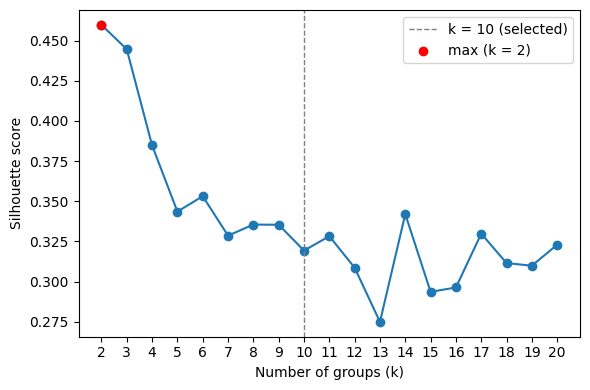

In [9]:
clusterer = TopicClusterer(modeler, auto_group=False)
fig_s2_silhouette(clusterer, k_min=2, k_max=20, out_path=f'{OUT}/fig_s2_silhouette.png')

## Table 1

In [10]:
import pandas as pd

counts = pd.Series(modeler.topics).value_counts()              # reduction-aware doc count per topic
info   = modeler.topic_model.get_topic_info()[["Topic", "Name"]]
total  = int(counts.sum())
t2g    = labeler.topic_to_group                                # {topic: 'Group_x'}
gname  = labeler.current_labels()                              # {'Group_x': 'Label'}

# topic -> readable label: prefer LLM topic labels from group_summaries, else BERTopic keywords
topic_label = {}
for s in labeler.group_summaries.values():
    if isinstance(s, dict) and s.get("topics") and s.get("topic_labels") \
       and len(s["topics"]) == len(s["topic_labels"]):
        topic_label.update({int(t): l for t, l in zip(s["topics"], s["topic_labels"])})
for _, r in info.iterrows():
    topic_label.setdefault(int(r["Topic"]), r["Name"])

td = pd.DataFrame([{"topic": t, "n": int(n), "group": gname.get(t2g.get(t), t2g.get(t))}
                   for t, n in counts.items() if t != -1])
if td["group"].isna().any():
    print("⚠ topics with no group mapping:", td[td["group"].isna()]["topic"].tolist())

table1 = (td.groupby("group")
            .apply(lambda d: pd.Series({
                "n": int(d["n"].sum()),
                "# topics": d["topic"].nunique(),
                "Representative topics": "; ".join(
                    topic_label.get(t, str(t))
                    for t in d.sort_values("n", ascending=False)["topic"].head(3))}))
            .reset_index().rename(columns={"group": "Group"}))
table1["%"] = (100 * table1["n"] / total).round(1)
table1 = table1[["Group", "n", "%", "# topics", "Representative topics"]] \
            .sort_values("n", ascending=False).reset_index(drop=True)

n_out = int(counts.get(-1, 0))
print(f"Total {total} | categorized {total - n_out} | residual outliers {n_out} "
      f"({100*n_out/total:.1f}%) | groups {len(table1)}")
table1.to_csv(f"{OUT}/table1_groups.csv", index=False)
table1

/tmp/ipykernel_1120/2605987424.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: pd.Series({


Total 34805 | categorized 29213 | residual outliers 5592 (16.1%) | groups 10


,Group,n,%,# topics,Representative topics
0,Nutrition and Exercise for Cardiovascular Heal...,12590,36.2,8,Cholesterol and Heart Health; Low-Carbohydrate...
1,Lipid Management and Cardiovascular Risk Reduc...,4231,12.2,8,Lipoprotein(a) Risk Factors and Management; Fa...
2,Hormone and Lipid Profile Analysis for Cardiov...,2198,6.3,6,Hormone and Metabolic Panel for Males; Lipid P...
3,Cardiovascular Risk Assessment and Unexplained...,1931,5.5,5,Infertility and TTC (Trying to Conceive) Journ...
4,Plant-Based Diets and Metabolic Health,1923,5.5,5,Health benefits of plant-based diets.; Health ...
5,Lipidomics and Cardiovascular Disease Risk Fac...,1844,5.3,5,Causal role of LDL cholesterol in cardiovascul...
6,Cholesterol Management and Oxidative Stress Mi...,1292,3.7,5,Lipitor Online Purchase and Sales; Crestor (Ro...
7,PCSK9 Inhibitors for Hypercholesterolemia Mana...,1244,3.6,6,Lipoprotein(a) testing and management; Free He...
8,Niacin and Lipoprotein(a) Effects on Cholester...,1165,3.3,5,Heart Health and Cholesterol Management; Lipop...
9,ApoB and Lp(a) Testing for Cardiovascular Risk...,795,2.3,4,Cholesterol and Lipid Profile Management; Fami...


##Table 2

In [11]:
import pandas as pd
df = reddit_df.copy()
df["year"] = pd.to_datetime(pd.to_numeric(df["created_utc"], errors="coerce"), unit="s", utc=True).dt.year

t2 = df.groupby(["year", "type_of_entry"]).size().unstack(fill_value=0)
for c in ("post", "comment"):
    if c not in t2.columns: t2[c] = 0
t2 = t2[["post", "comment"]]
t2["total"] = t2.sum(axis=1)
t2.loc["TOTAL"] = t2.sum()

print(f'N = {len(df)} | posts {int(df.type_of_entry.eq("post").sum())} | '
      f'comments {int(df.type_of_entry.eq("comment").sum())} | '
      f'span {int(df.year.min())}–{int(df.year.max())}')
t2.to_csv(f"{OUT}/table2_by_year.csv")
t2

N = 34814 | posts 8308 | comments 26506 | span 2008–2025


type_of_entry,post,comment,total
year,,,
2008,2,0,2
2009,3,4,7
2010,2,4,6
2011,20,301,321
2012,64,519,583
2013,78,666,744
2014,184,778,962
2015,1000,841,1841
2016,146,725,871


## Supplemental table 1 - topics

In [11]:
import pandas as pd

counts = pd.Series(modeler.topics).value_counts()          # post-reduction doc count per topic
total  = int(counts.sum())
info   = modeler.topic_model.get_topic_info().set_index("Topic")
t2g    = labeler.topic_to_group                            # {topic: 'Group_x'}
gname  = labeler.current_labels()                          # {'Group_x': 'Label'}

# topic -> readable label: prefer LLM topic labels in group_summaries, else BERTopic keyword name
topic_label = {}
for s in labeler.group_summaries.values():
    if isinstance(s, dict) and s.get("topics") and s.get("topic_labels") \
       and len(s["topics"]) == len(s["topic_labels"]):
        topic_label.update({int(t): l for t, l in zip(s["topics"], s["topic_labels"])})

def keywords(t, k=10):
    try:    return ", ".join(w for w, _ in modeler.topic_model.get_topic(t)[:k] if w)
    except Exception: return ""

def exemplar(t, n=240):
    try:
        docs = modeler.topic_model.get_representative_docs(t)
        return (docs[0][:n] + "…") if docs else ""
    except Exception: return ""

rows = []
for t in sorted(x for x in counts.index if x != -1):
    g = t2g.get(t)
    nm = info.loc[t, "Name"] if t in info.index else str(t)
    rows.append({
        "Topic": int(t),
        "Label": topic_label.get(int(t), nm),
        "Parent group": gname.get(g, g),
        "n": int(counts.get(t, 0)),
        "%": round(100 * int(counts.get(t, 0)) / total, 2),
        "Top keywords": keywords(t),
        "Exemplar discussion": exemplar(t),
    })

suppS1 = (pd.DataFrame(rows)
            .sort_values(["Parent group", "n"], ascending=[True, False])
            .reset_index(drop=True))

n_out = int(counts.get(-1, 0))
print(f"{len(suppS1)} topics | total {total} | residual outliers {n_out} ({100*n_out/total:.1f}%)")
suppS1.to_csv(f"{OUT}/suppS1_topics.csv", index=False)
suppS1

57 topics | total 34805 | residual outliers 5592 (16.1%)


,Topic,Label,Parent group,n,%,Top keywords,Exemplar discussion
0,20,Cholesterol and Lipid Profile Management,ApoB and Lp(a) Testing for Cardiovascular Risk...,374,1.07,"ldl, cholesterol, hdl, particle count, particl...","LDL cholesterol isn't a great marker, what you..."
1,35,Familial Hypercholesterolemia and Cardiovascul...,ApoB and Lp(a) Testing for Cardiovascular Risk...,149,0.43,"market, fh, chocolate, familial, familial hype...","Recently, Polychronopoulos and Tziomalos revie..."
2,39,Gene Editing for Cholesterol Treatment,ApoB and Lp(a) Testing for Cardiovascular Risk...,137,0.39,"gene, editing, pcsk9, gene therapy, therapy, g...",Ionis Pharmaceuticals (IONS). **IONIS PHARMACE...
3,46,Early-onset Alzheimer's disease risk factors a...,ApoB and Lp(a) Testing for Cardiovascular Risk...,135,0.39,"alzheimer, amyloid, alzheimer disease, apoe, b...",The title of the post is a copy and paste from...
4,3,Infertility and TTC (Trying to Conceive) Journey,Cardiovascular Risk Assessment and Unexplained...,792,2.28,"cycle, progesterone, days, day, cycles, ovulat...",**Cycle:** 5 **Age + Partner's age (if relevan...
5,15,High Cholesterol and Cardiovascular Risk Asses...,Cardiovascular Risk Assessment and Unexplained...,428,1.23,"statin, lp, risk, high, ldl, cac, diet, need, ...",I am not a doctor but have been battling chole...
6,18,Undiagnosed Neurological Condition,Cardiovascular Risk Assessment and Unexplained...,350,1.01,"mri, ms, symptoms, pain, neurologist, like, ve...",Where do I go from here?. In my desperate sear...
7,27,High LDL Particles and Lp(a) despite Low ApoB ...,Cardiovascular Risk Assessment and Unexplained...,229,0.66,"lp, ldl, high, risk, apob, numbers, test, chol...",Even higher Lp(a) after lifestyle change. 380 ...
8,44,Chest Pain and Tachycardia Medical Mystery,Cardiovascular Risk Assessment and Unexplained...,132,0.38,"chest, pain, heart, normal, ve, heart rate, ju...","Neurologists, Cardiologists, Rheumatologists -..."
9,11,Lipitor Online Purchase and Sales,Cholesterol Management and Oxidative Stress Mi...,469,1.35,"lipitor, atorvastatin, buy, purchase, generic,...",Buy Lipitor Retail Price in Birmingham - Lipit...


## Supplemental Figure 2 - subreddit distribution

3673 subreddits | top20 57.8%


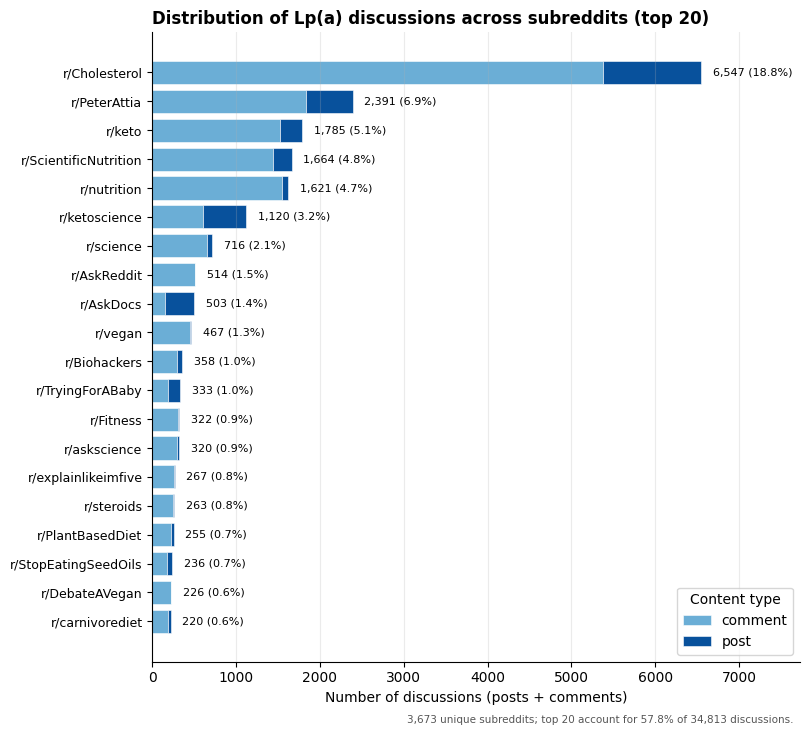

In [12]:
import matplotlib.pyplot as plt, numpy as np
d = reddit_df.dropna(subset=["subreddit"]); N = len(d); U = d["subreddit"].nunique()
tot = d["subreddit"].value_counts(); top = tot.head(20).index[::-1]
pc = (d[d.subreddit.isin(top)].groupby(["subreddit","type_of_entry"]).size()
        .unstack(fill_value=0).reindex(top))
for c in ("post","comment"):
    if c not in pc: pc[c] = 0
fig, ax = plt.subplots(figsize=(8.2, 7.4)); y = np.arange(len(top))
ax.barh(y, pc["comment"], color="#6BAED6", label="comment", edgecolor="white", linewidth=0.4)
ax.barh(y, pc["post"], left=pc["comment"], color="#08519C", label="post", edgecolor="white", linewidth=0.4)
for i, s in enumerate(top):
    n = int(tot[s]); ax.text(n + N*0.004, i, f"{n:,} ({100*n/N:.1f}%)", va="center", fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(["r/"+s for s in top], fontsize=9)
ax.set_xlabel("Number of discussions (posts + comments)")
ax.set_title("Distribution of Lp(a) discussions across subreddits (top 20)", loc="left", fontweight="bold")
ax.legend(title="Content type", loc="lower right"); ax.set_xlim(0, int(tot[top].max())*1.18)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
ax.grid(axis="x", alpha=0.25)
ax.text(0.99, -0.085, f"{U:,} unique subreddits; top 20 account for {100*tot.head(20).sum()/N:.1f}% of {N:,} discussions.",
        transform=ax.transAxes, ha="right", va="top", fontsize=7.5, color="#555555")
fig.tight_layout(); fig.savefig(f"{OUT}/SuppFig_subreddits.png", dpi=300, bbox_inches="tight")
fig.savefig(f"{OUT}/SuppFig_subreddits.pdf", bbox_inches="tight")
print(f"{U} subreddits | top20 {100*tot.head(20).sum()/N:.1f}%")

#Supplemental Table - example docs

In [ ]:
import pandas as pd, re
df = pd.read_json("filtered_df_3.25.26.json")
txt = (df.get("title","").fillna("").astype(str)+" "+df.get("selftext","").fillna("").astype(str)+" "+df.get("body","").fillna("").astype(str))
low = txt.str.lower(); sub = df.get("subreddit","").fillna("").astype(str)
LPA = r"lp\s*\(a\)|lipoprotein\s*\(?a\)?|\blp-?a\b"
has_lpa = low.str.contains(LPA, regex=True)

def theme(pat, extra=None, k=8, lo=45, hi=235, need_q=False):
    m = has_lpa & low.str.contains(pat, regex=True)
    if extra is not None: m = m & low.str.contains(extra, regex=True)
    if need_q: m = m & low.str.contains(r"\?", regex=True)
    out, seen = [], set()
    for i in df.index[m]:
        s = re.sub(r"\s+", " ", txt.loc[i]).strip()
        if not (lo <= len(s) <= hi): continue
        key = s[:60].lower()
        if key in seen: continue
        seen.add(key); out.append((("r/"+sub.loc[i]) if sub.loc[i] else "", s))
        if len(out) >= k: break
    return out

THEMES = {
 "Cost / access / coverage": (r"not covered|out[- ]of[- ]pocket|pay(?:ing)? for|afford|copay|co-pay|deductible|\$\s?\d|charged|reimburs|\binsurance\b|\bmedicare\b|covered by", None, False),
 "Interpreting a result (uncertainty)": (r"is (?:this|it|that|my|an?) .{0,25}(?:bad|high|normal|concerning|serious|ok|dangerous)|what does .{0,20}mean|should i (?:be )?worr|can (?:someone|anyone) explain|do i need to worry|is (?:that|this) (?:good|bad|normal)", None, True),
 "Marker discordance (Lp(a) vs LDL/apoB)": (r"apob|apo b|\bldl\b", r"despite|even though|but my|but i|however|only my|normal|low|elevated", False),
 "Family / genetic risk & screening": (r"\bfamily\b|siblings?|\bkids\b|children|relatives?|parents?|father|mother|brother|sister|\bson\b|daughter|hereditary|inherited|genetic", r"test|screen|check", False),
}
rows = []
for th, (pat, extra, need_q) in THEMES.items():
    for srd, s in theme(pat, extra, need_q=need_q):
        rows.append({"Theme": th, "Subreddit": srd, "Verbatim snippet": s, "Paraphrased for publication": ""})
pd.DataFrame(rows).to_csv("SuppTable_representative_quotes.csv", index=False)

##No-legend figure B

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

_TOL = ["#4477AA","#EE6677","#228833","#CCBB44","#66CCEE",
        "#AA3377","#BBBBBB","#EE8866","#77AADD","#999933"]

def fig1b_nolegend(emb2d, labels, out="Fig1B_nolegend",
                   figsize=(7.2, 7.2), s=7, alpha=0.6):
    """Square UMAP scatter, coloured by group, NO legend. Returns the
    {group: colour} map so the standalone legend matches exactly."""
    emb2d = np.asarray(emb2d); labels = np.asarray(labels)
    uniq = sorted(set(labels))
    colors = {g: _TOL[i % len(_TOL)] for i, g in enumerate(uniq)}
    fig, ax = plt.subplots(figsize=figsize)
    for g in uniq:
        m = labels == g
        ax.scatter(emb2d[m, 0], emb2d[m, 1], c=[colors[g]], s=s,
                   alpha=alpha, linewidths=0, rasterized=True)
    ax.set_xlabel("UMAP-1", fontsize=11); ax.set_ylabel("UMAP-2", fontsize=11)
    ax.set_xticks([]); ax.set_yticks([]); ax.margins(0.02)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    fig.tight_layout()
    for ext in ("pdf", "png", "svg"):
        fig.savefig(f"{out}.{ext}", dpi=300, bbox_inches="tight")
    return colors

In [18]:
def fig1b_legend_only(colors, out="Fig1B_legend",
                      ncol=2, figsize=(8.5, 2.0)):
    """Standalone legend strip using the FULL group names, colours
    matched to fig1b_nolegend via the returned `colors` dict."""
    handles = [Line2D([0], [0], marker='o', linestyle='', markersize=10,
                      markerfacecolor=c, markeredgecolor='none', label=g)
               for g, c in colors.items()]
    fig = plt.figure(figsize=figsize)
    fig.legend(handles=handles, loc='center', ncol=ncol, frameon=False,
               fontsize=10, title="Topic groups", title_fontsize=11,
               handletextpad=0.5, columnspacing=1.6, labelspacing=0.9)
    for ext in ("pdf", "png", "svg"):
        fig.savefig(f"{out}.{ext}", dpi=300, bbox_inches="tight")

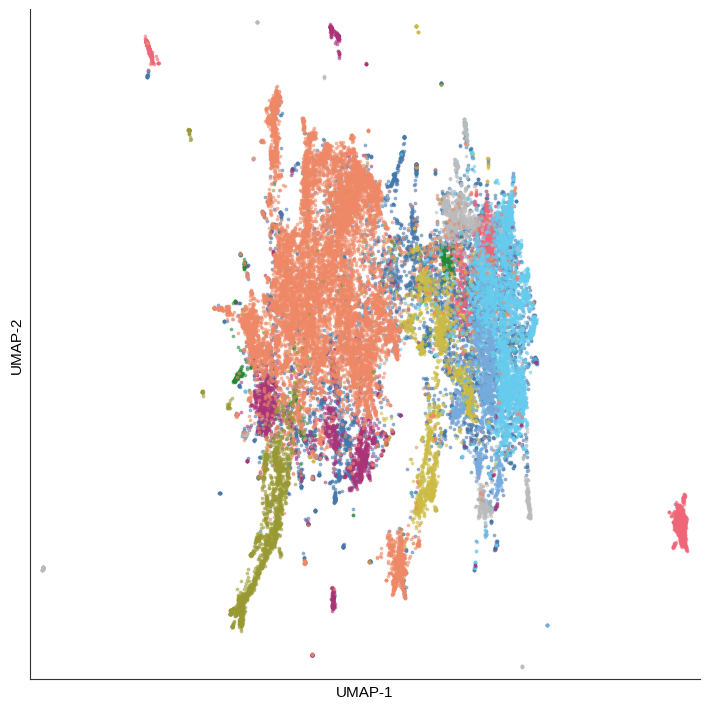

<Figure size 850x200 with 0 Axes>

In [19]:
colors = fig1b_nolegend(emb2d, labels, out=f'{OUT}/Fig1B_nolegend')   # square panel, no legend
fig1b_legend_only(colors, out=f'{OUT}/Fig1B_legend')                   # matching legend strip